# Netflix Exploratory Data Analysis
This notebook explores the Netflix content catalog to identify trends in formats (Movies vs TV Shows), release years, top producing countries, and popular genres.


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('netflix_titles.csv')
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [7]:
# Basic Cleaning
df['primary_country'] = df['country'].apply(lambda x: str(x).split(',')[0] if pd.notnull(x) else 'Unknown')
df_recent = df[df['release_year'] >= 2000]


C:\Users\Awel\AppData\Local\Temp\ipykernel_15052\2608348925.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='Set2')


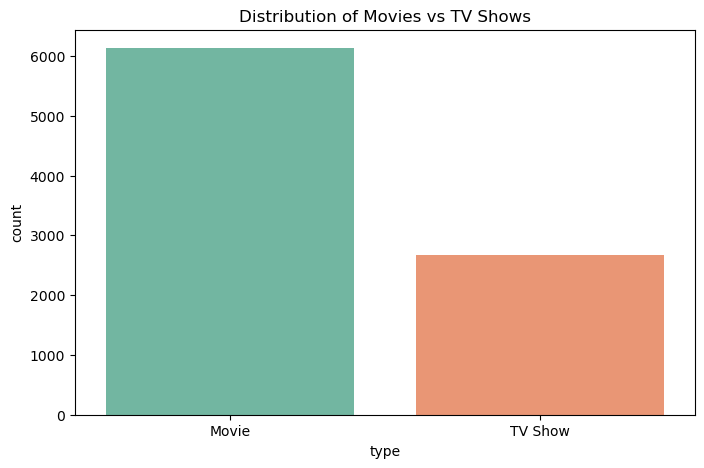

In [8]:
# 1. Movies vs TV Shows
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='type', palette='Set2')
plt.title('Distribution of Movies vs TV Shows')
plt.show()


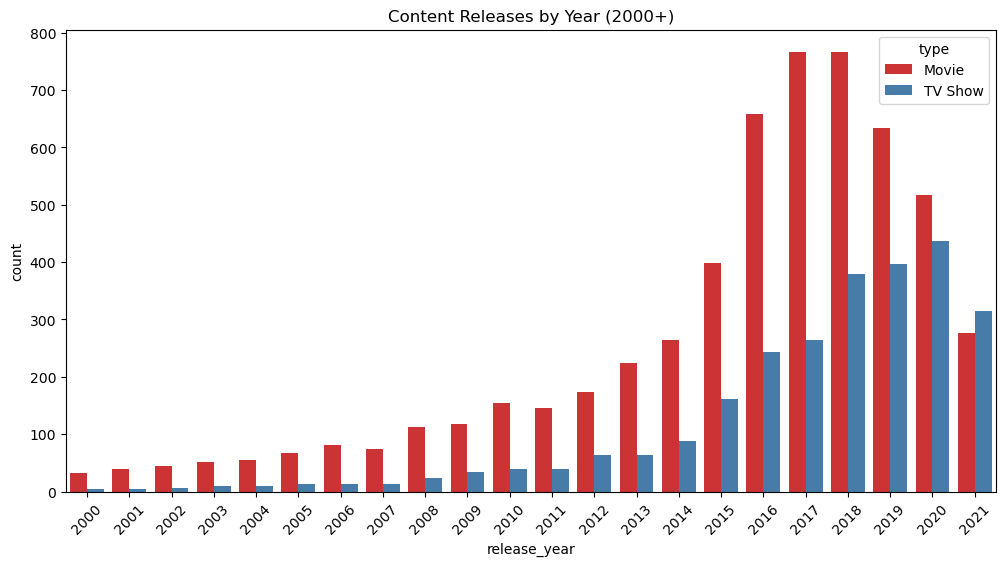

In [9]:
# 2. Content releases over the last 20 years
plt.figure(figsize=(12, 6))
sns.countplot(data=df_recent, x='release_year', hue='type', palette='Set1')
plt.title('Content Releases by Year (2000+)')
plt.xticks(rotation=45)
plt.show()


C:\Users\Awel\AppData\Local\Temp\ipykernel_15052\2713928904.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_countries.index, x=top_countries.values, palette='viridis')


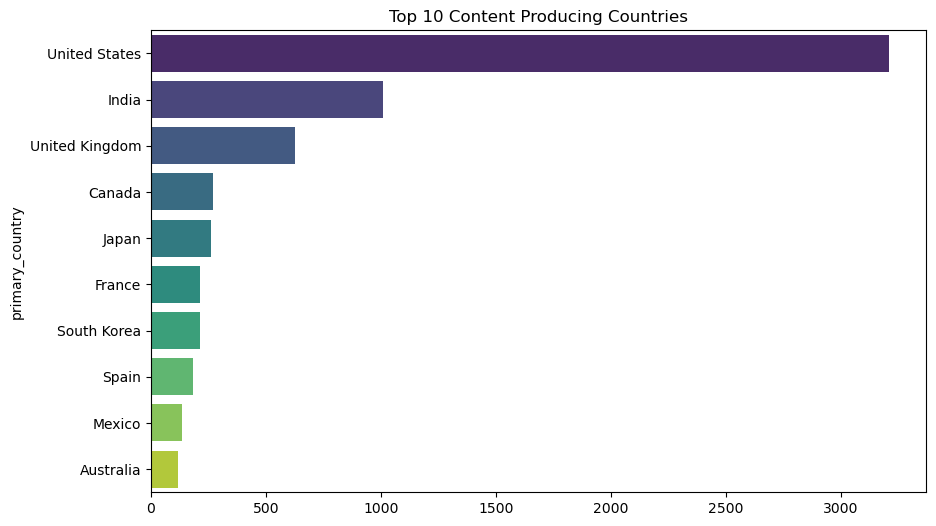

In [10]:
# 3. Top 10 Producing Countries
top_countries = df[df['primary_country'] != 'Unknown']['primary_country'].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(y=top_countries.index, x=top_countries.values, palette='viridis')
plt.title('Top 10 Content Producing Countries')
plt.show()


C:\Users\Awel\AppData\Local\Temp\ipykernel_15052\1432532523.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', order=df['rating'].value_counts().index, palette='magma')


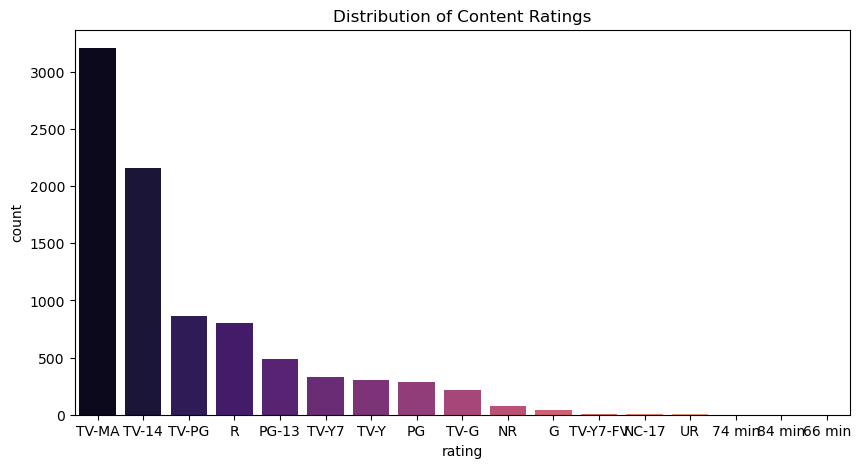

In [11]:
# 4. Ratings Distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='rating', order=df['rating'].value_counts().index, palette='magma')
plt.title('Distribution of Content Ratings')
plt.show()


C:\Users\Awel\AppData\Local\Temp\ipykernel_15052\2148939655.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_genres.index, x=top_genres.values, palette='cubehelix')


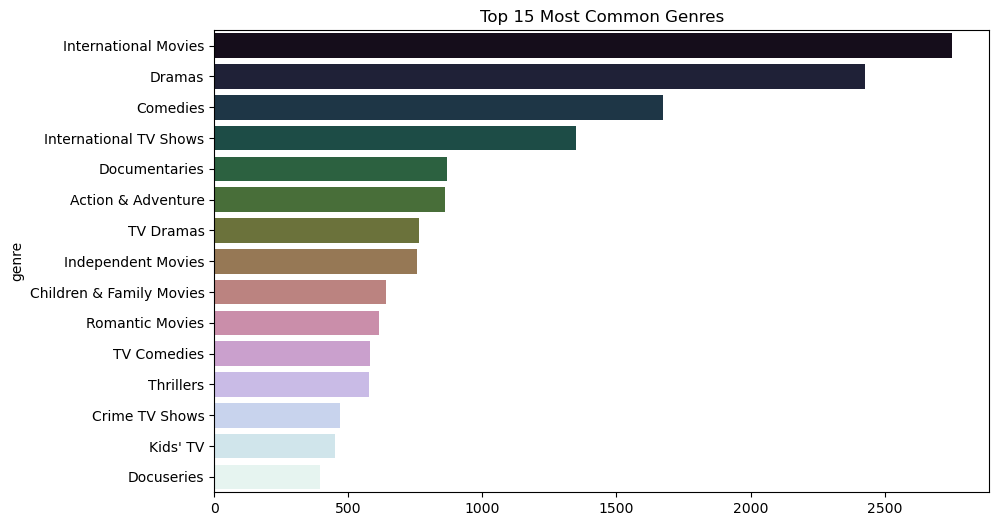

In [12]:
# 5. Top 15 Genres
df['genre'] = df['listed_in'].apply(lambda x: [g.strip() for g in str(x).split(',')])
df_exploded = df.explode('genre')
top_genres = df_exploded['genre'].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(y=top_genres.index, x=top_genres.values, palette='cubehelix')
plt.title('Top 15 Most Common Genres')
plt.show()


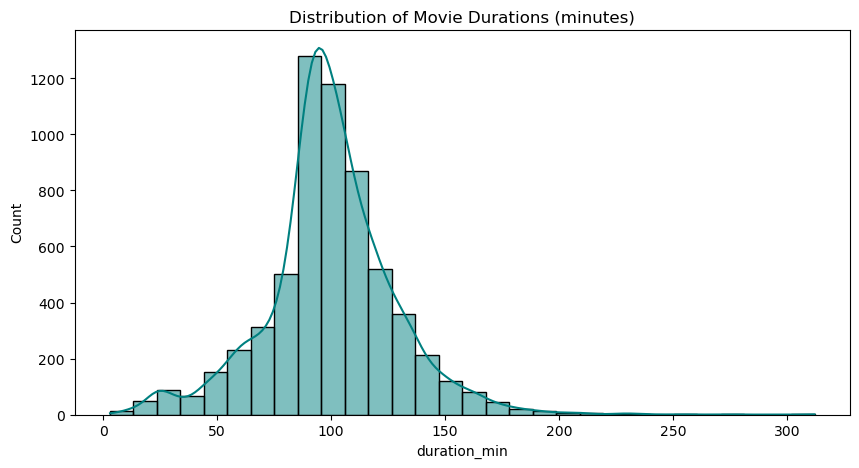

In [13]:
# 6. Duration Analysis (Movies)
movies = df[df['type'] == 'Movie'].copy()
# Extract integer from duration e.g. "90 min"
movies['duration_min'] = movies['duration'].str.extract('(\d+)').astype(float)

plt.figure(figsize=(10, 5))
sns.histplot(movies['duration_min'], bins=30, kde=True, color='teal')
plt.title('Distribution of Movie Durations (minutes)')
plt.show()
